# Laboratorio UNIR — Evaluación de la segmentación

Comparación de Otsu y K-means sobre cinco fotografías reales de La Candelaria, Bogotá. La referencia (`foreground_urbano`) proviene de polígonos manuales independientes.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from segmentation_lab import otsu_threshold, kmeans_segment, binary_metrics, confusion_matrix
image_dir = ROOT / 'data' / 'real' / 'images'
mask_dir = ROOT / 'data' / 'real' / 'masks'
annotations = json.loads((ROOT / 'data' / 'real' / 'annotations.json').read_text(encoding='utf-8'))
if len(list(mask_dir.glob('*.png'))) != 5:
    exec((ROOT / 'scripts' / 'build_real_masks.py').read_text(encoding='utf-8'))


In [2]:
rows = []
predictions = {}
for image_path in sorted(image_dir.glob('*.jpg')):
    name = image_path.name
    image = np.asarray(Image.open(image_path).convert('L'))
    truth = np.asarray(Image.open(mask_dir / f'{image_path.stem}_mask.png').convert('L')) > 0
    threshold, otsu_mask = otsu_threshold(image)
    centroids, kmeans_mask = kmeans_segment(image, seed=7)
    predictions[name] = {'image': image, 'truth': truth, 'Otsu': otsu_mask, 'K-means': kmeans_mask}
    rows.append({'image': name, 'method': 'Otsu', 'parameter': f'threshold={threshold}', **binary_metrics(truth, otsu_mask)})
    rows.append({'image': name, 'method': 'K-means', 'parameter': f'centroids={np.round(centroids, 2)}', **binary_metrics(truth, kmeans_mask)})
rows


[{'image': '01_calle_mural.jpg',
  'method': 'Otsu',
  'parameter': 'threshold=99',
  'iou': 0.48355226146176206,
  'dice': 0.6518843643368682,
  'precision': 0.8293177974724404,
  'recall': 0.5369939353459489,
  'accuracy': 0.5311968430826369},
 {'image': '01_calle_mural.jpg',
  'method': 'K-means',
  'parameter': 'centroids=[ 53.43 145.39]',
  'iou': 0.48355226146176206,
  'dice': 0.6518843643368682,
  'precision': 0.8293177974724404,
  'recall': 0.5369939353459489,
  'accuracy': 0.5311968430826369},
 {'image': '02_casa_cuervo.jpg',
  'method': 'Otsu',
  'parameter': 'threshold=91',
  'iou': 0.3440256528501157,
  'dice': 0.5119331645502173,
  'precision': 1.0,
  'recall': 0.3440256528501157,
  'accuracy': 0.3440256528501157},
 {'image': '02_casa_cuervo.jpg',
  'method': 'K-means',
  'parameter': 'centroids=[ 41.36 142.91]',
  'iou': 0.33751889829282405,
  'dice': 0.5046940252188209,
  'precision': 1.0,
  'recall': 0.33751889829282405,
  'accuracy': 0.33751889829282405},
 {'image': '0

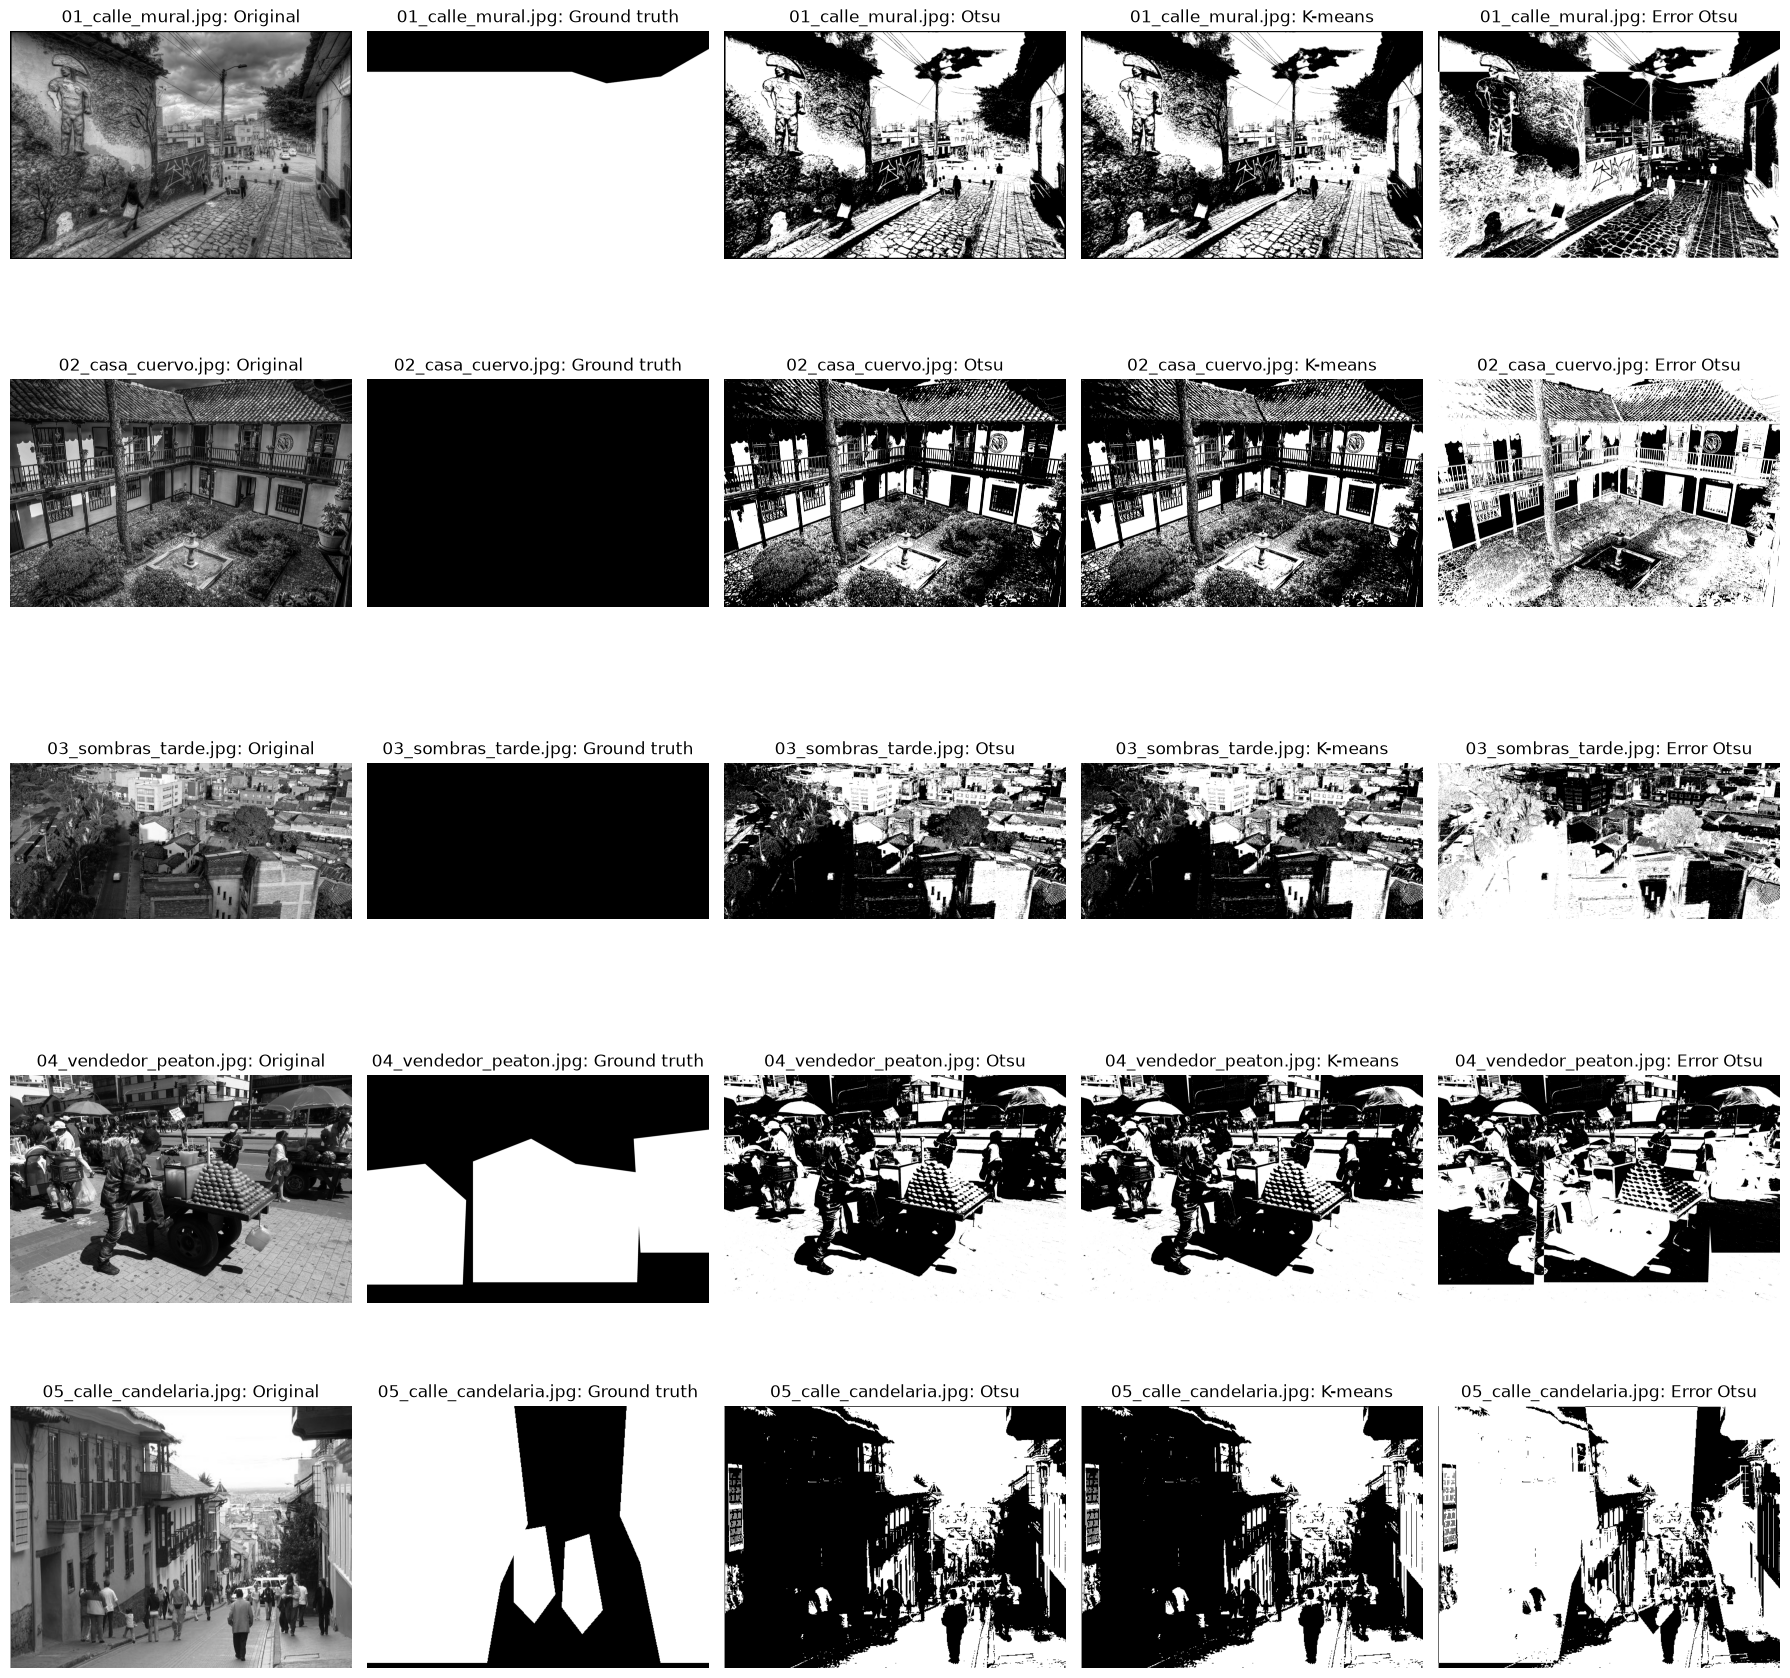

In [3]:
fig, axes = plt.subplots(5, 5, figsize=(18, 18))
for row, (name, result) in enumerate(predictions.items()):
    data = [result['image'], result['truth'], result['Otsu'], result['K-means'], result['Otsu'] ^ result['truth']]
    titles = ['Original', 'Ground truth', 'Otsu', 'K-means', 'Error Otsu']
    for axis, item, title in zip(axes[row], data, titles):
        axis.imshow(item, cmap='gray'); axis.set_title(f'{name}: {title}'); axis.axis('off')
plt.tight_layout(); plt.show()


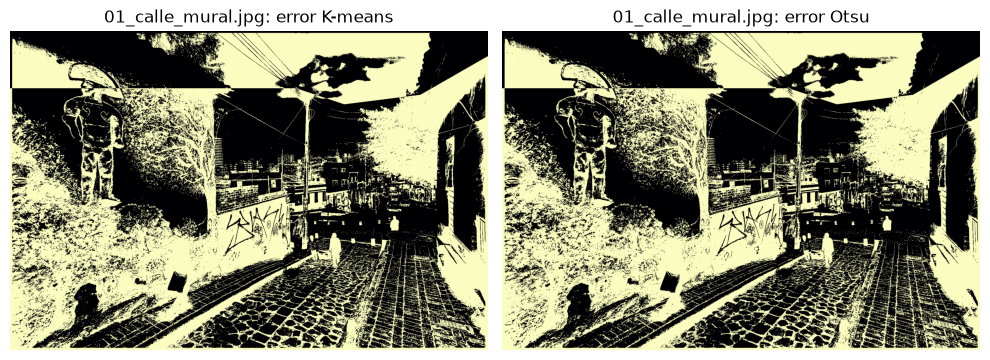

01_calle_mural.jpg Otsu [[198716, 194590], [815212, 945482]] K-means [[198716, 194590], [815212, 945482]]


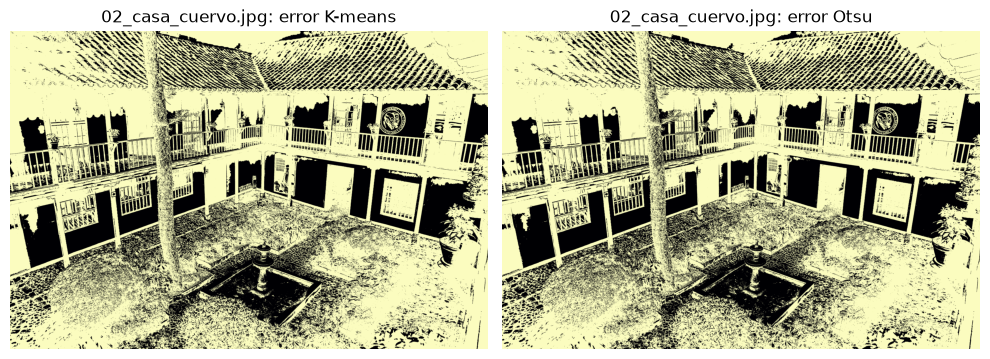

02_casa_cuervo.jpg Otsu [[0, 0], [14509103, 7609297]] K-means [[0, 0], [14653022, 7465378]]


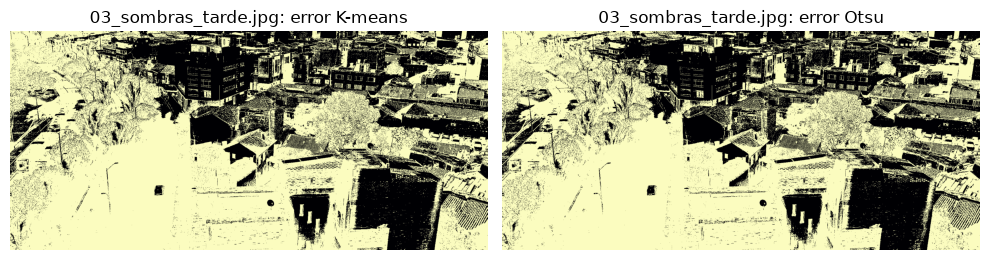

03_sombras_tarde.jpg Otsu [[0, 0], [1150278, 681722]] K-means [[0, 0], [1150278, 681722]]


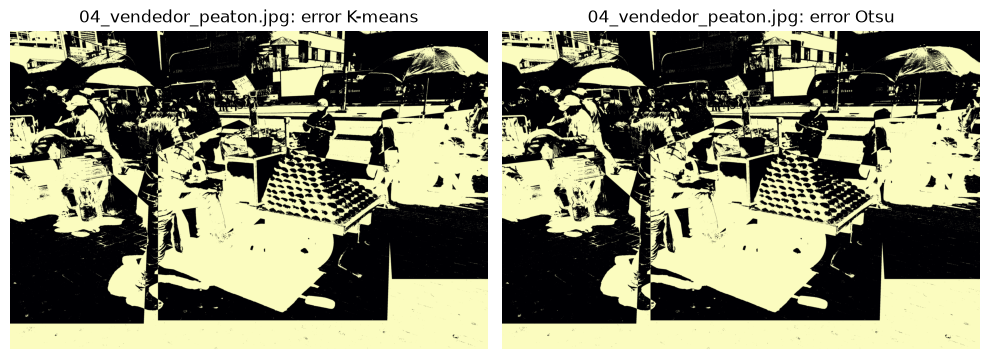

04_vendedor_peaton.jpg Otsu [[4410620, 4296792], [4455588, 4735628]] K-means [[4410620, 4296792], [4455588, 4735628]]


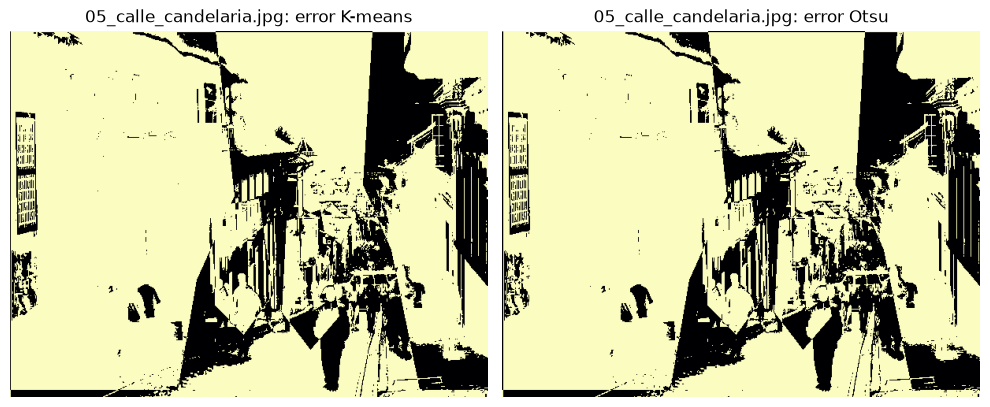

05_calle_candelaria.jpg Otsu [[29898, 57311], [153793, 40788]] K-means [[29499, 57710], [153086, 41495]]


In [4]:
for name, result in predictions.items():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(result['K-means'] ^ result['truth'], cmap='magma'); axes[0].set_title(f'{name}: error K-means')
    axes[1].imshow(result['Otsu'] ^ result['truth'], cmap='magma'); axes[1].set_title(f'{name}: error Otsu')
    for axis in axes: axis.axis('off')
    plt.tight_layout(); plt.show()
    print(name, 'Otsu', confusion_matrix(result['truth'], result['Otsu']).tolist(), 'K-means', confusion_matrix(result['truth'], result['K-means']).tolist())


## Lectura de resultados

Cada fila de `rows` compara una predicción con la máscara manual. IoU y Dice miden solapamiento; precisión y recall separan FP/FN; la matriz se presenta como `[[TN, FP], [FN, TP]]`. Las máscaras solo se rasterizan desde `annotations.json`.
